In [1]:
from tqdm import tqdm
from astropy.table import Table
import numpy as np
import h5py
import pandas as pd
import data
import matplotlib.pyplot as plt
import sample
from scipy import stats
from multicam.models import MultiCAM

TNG_H = 0.6774

In [2]:
def _convert_tng_position(tng_pos):
    """Convert TNG positions from from kiloparsecs to megaparsecs
    Args: 
        tng_pos: column of an astropy table, i.e. t['x']
    Return:
        Column in new units of megaparsecs
    """
    pos = tng_pos/1000
    return pos


def _check_flag(table):
    """Filters astropy table such that 'SubhaloFlag' is True
    Args:
        table: astropy table created with import_subhalo
    Return: 
        Outputs the filtered astropy table
    """
    t = table[(table['SubhaloFlag'] == 1)]
    return t


def import_subhalo(file_number, directory, check_subhalo_flag):
    """Reads in data in the form of h5py files from TNG100
    Args:
        file_number: the desired number of files to be read in
        directory: string that details path from location 
        of notebook to dataset, i.e. 'data/subhalo_data'
    Return:
        Outputs an astropy table with 'ID', 'SubhaloMass', 
        'SubhaloFlag','StellarMass', 'x', 'y', 'z','SFR',
        'logSubhaloMass' and 'logStellarMass' as keys
    Note:
        'StellarMass' units Msun/h
        'logStellarMass' = log10('StellarMass')
    """
    subhalo_ids = []
    subhalo_mass = []
    subhalo_flag = []
    stellar_mass = []
    x_position = []
    y_position = []
    z_position = []
    sfr_list = []
    vmax_list = []
    spin_list = []
    vdisp_list = []
    halfmass_list = []
    
    count = 0
    
    for ii in tqdm(range(0, file_number + 1)):
        filename = f'{directory}/fof_subhalo_tab_099.{ii}.hdf5' 
        with h5py.File(filename, 'r') as f:
            if 'SubhaloMass' in f['Subhalo'].keys(): 
                for s in f['Subhalo']['SubhaloMass']:
                    subhalo_mass.append(s)
                    subhalo_ids.append(count)
                    count+=1
                for flag in f['Subhalo']['SubhaloFlag']:
                    subhalo_flag.append(flag)
                for star in f['Subhalo']['SubhaloMassInRadType'][:,4]: 
                    stellar_mass.append(star)
                for (x, y, z) in f['Subhalo']['SubhaloPos'][:]:
                    x_position.append(x)
                    y_position.append(y)
                    z_position.append(z) 
                for sfr in f['Subhalo']['SubhaloSFR']:
                    sfr_list.append(sfr) # units Msun/yr
                for v in f['Subhalo']['SubhaloVmax']:
                    vmax_list.append(v)
                for vd in f['Subhalo']['SubhaloVelDisp']:
                    vdisp_list.append(vd)  
                for (spinx, spiny, spinz) in f['Subhalo']['SubhaloSpin'][:]:
                    spin_list.append(np.sqrt(spinx**2 + spiny**2 + spinz**2))
                for halfmass in f['Subhalo']['SubhaloHalfmassRad']:
                    halfmass_list.append(halfmass)
                    
    t = Table(data = [subhalo_ids, subhalo_mass, subhalo_flag, stellar_mass, 
                      x_position, y_position, z_position, sfr_list, vmax_list, 
                      vdisp_list, spin_list, halfmass_list], 
              names = ['ID', 'SubhaloMass', 'SubhaloFlag', 'StellarMass', 'x', 'y', 'z', 
                       'SFR', 'Vmax', 'Vdisp', 'SubhaloSpin', 'SubhaloHalfmassRad'])
    
    if check_subhalo_flag == True:
        t = _check_flag(t)

    # Convert from TNG units to Msun/h
    t['StellarMass'] = t['StellarMass']*1e10 
    t['SubhaloMass'] = t['SubhaloMass']*1e10 

    # Create logSubhaloMass and logStellarMass 
    t['logSubhaloMass'] = np.log10(t['SubhaloMass'])
    t['logStellarMass'] = np.log10(t['StellarMass'])
    
    t['x'] = _convert_tng_position(t['x'])
    t['y'] = _convert_tng_position(t['y'])
    t['z'] = _convert_tng_position(t['z'])
    return t

In [3]:
file_number = 447
directory = 'data/subhalo_data' 
check_subhalo_flag = False
subhalo_data = import_subhalo(file_number, directory, check_subhalo_flag)

100%|█████████████████████████████████████████████████████████████████████████████████| 448/448 [02:04<00:00,  3.60it/s]
/tmp/ipykernel_988/2930798925.py:94: RuntimeWarning: divide by zero encountered in log10
  t['logStellarMass'] = np.log10(t['StellarMass'])


In [4]:
subhalo_data

ID,SubhaloMass,SubhaloFlag,StellarMass,x,y,z,SFR,Vmax,Vdisp,SubhaloSpin,SubhaloHalfmassRad,logSubhaloMass,logStellarMass
int64,float32,bool,float32,float32,float32,float32,float32,float32,float32,float64,float32,float32,float32
0,274779360000000.0,True,1638342200000.0,0.8490914,26.326996,18.306934,2.227189,999.38513,603.87506,30622.779279053004,607.9657,14.438984,12.214405
1,36666230000000.0,True,257310150000.0,0.106473334,24.633322,16.900553,0.41328505,514.7759,333.89325,23274.55931638198,300.9588,13.564266,11.410457
2,7734555000000.0,True,288526800000.0,0.85311234,26.725748,17.51068,17.392204,461.64127,297.57727,6911.156111195774,78.249374,12.888435,11.460186
3,3391331000000.0,True,81590350000.0,0.24545503,26.517372,15.888749,5.0793796,291.93655,159.56184,3582.8616129869706,108.97078,12.53037,10.911639
4,3253667000000.0,True,62764753000.0,0.76878434,26.51829,15.530523,1.4146897,294.43298,168.74423,2915.8886742821046,85.20622,12.512373,10.797716
5,2980181200000.0,True,87703300000.0,1.4265924,26.341442,19.041204,0.88655853,311.58014,191.30777,1816.5920149934373,66.2267,12.474242,10.943016
6,2068306100000.0,True,145728470000.0,0.9047556,26.611113,17.832447,2.1843414,369.4471,217.87068,161.04737703693007,34.035828,12.315615,11.163545
7,1378258800000.0,True,85616484000.0,1.4113867,26.663296,17.276665,0.0,336.25394,164.36949,1037.3456953534633,38.208107,12.139331,10.932557
8,1185448300000.0,True,104240370000.0,0.8358986,26.505188,17.452578,0.0,329.11383,186.55058,328.14132588767404,29.298994,12.073883,11.018036


In [5]:
color_data = data.import_color('data/color_data')

In [6]:
color_data

,sdss_u,sdss_g,sdss_r,sdss_i,sdss_z,wfc_acs_f606w,des_y,jwst_f150w,subfind_id
0,-21.400572,-23.256830,-24.071045,-24.477274,-24.844450,-23.948242,-25.025240,-25.319426,0
1,-20.209169,-21.945702,-22.715570,-23.104830,-23.444975,-22.598524,-23.602861,-23.875483,1
2,-20.517130,-22.175474,-22.930420,-23.319283,-23.665720,-22.814957,-23.829544,-24.111971,2
3,-20.308001,-21.670481,-22.270124,-22.612875,-22.929995,-22.174856,-23.081690,-23.360138,3
4,-18.997976,-20.636168,-21.383369,-21.771263,-22.104784,-21.268999,-22.255264,-22.532751,4
...,...,...,...,...,...,...,...,...,...
4371206,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4371206
4371207,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4371207
4371208,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4371208
4371209,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4371209


In [7]:
subhalo_data['g-i'] = color_data['sdss_g'] - color_data['sdss_i'] 

In [8]:
subhalo_data

ID,SubhaloMass,SubhaloFlag,StellarMass,x,y,z,SFR,Vmax,Vdisp,SubhaloSpin,SubhaloHalfmassRad,logSubhaloMass,logStellarMass,g-i
int64,float32,bool,float32,float32,float32,float32,float32,float32,float32,float64,float32,float32,float32,float32
0,274779360000000.0,True,1638342200000.0,0.8490914,26.326996,18.306934,2.227189,999.38513,603.87506,30622.779279053004,607.9657,14.438984,12.214405,1.2204437
1,36666230000000.0,True,257310150000.0,0.106473334,24.633322,16.900553,0.41328505,514.7759,333.89325,23274.55931638198,300.9588,13.564266,11.410457,1.1591282
2,7734555000000.0,True,288526800000.0,0.85311234,26.725748,17.51068,17.392204,461.64127,297.57727,6911.156111195774,78.249374,12.888435,11.460186,1.1438084
3,3391331000000.0,True,81590350000.0,0.24545503,26.517372,15.888749,5.0793796,291.93655,159.56184,3582.8616129869706,108.97078,12.53037,10.911639,0.94239426
4,3253667000000.0,True,62764753000.0,0.76878434,26.51829,15.530523,1.4146897,294.43298,168.74423,2915.8886742821046,85.20622,12.512373,10.797716,1.1350956
5,2980181200000.0,True,87703300000.0,1.4265924,26.341442,19.041204,0.88655853,311.58014,191.30777,1816.5920149934373,66.2267,12.474242,10.943016,1.1248665
6,2068306100000.0,True,145728470000.0,0.9047556,26.611113,17.832447,2.1843414,369.4471,217.87068,161.04737703693007,34.035828,12.315615,11.163545,1.1494961
7,1378258800000.0,True,85616484000.0,1.4113867,26.663296,17.276665,0.0,336.25394,164.36949,1037.3456953534633,38.208107,12.139331,10.932557,1.1967144
8,1185448300000.0,True,104240370000.0,0.8358986,26.505188,17.452578,0.0,329.11383,186.55058,328.14132588767404,29.298994,12.073883,11.018036,1.2085056


In [9]:
data = subhalo_data[(subhalo_data['SubhaloFlag'] == 1)]

In [10]:
data

ID,SubhaloMass,SubhaloFlag,StellarMass,x,y,z,SFR,Vmax,Vdisp,SubhaloSpin,SubhaloHalfmassRad,logSubhaloMass,logStellarMass,g-i
int64,float32,bool,float32,float32,float32,float32,float32,float32,float32,float64,float32,float32,float32,float32
0,274779360000000.0,True,1638342200000.0,0.8490914,26.326996,18.306934,2.227189,999.38513,603.87506,30622.779279053004,607.9657,14.438984,12.214405,1.2204437
1,36666230000000.0,True,257310150000.0,0.106473334,24.633322,16.900553,0.41328505,514.7759,333.89325,23274.55931638198,300.9588,13.564266,11.410457,1.1591282
2,7734555000000.0,True,288526800000.0,0.85311234,26.725748,17.51068,17.392204,461.64127,297.57727,6911.156111195774,78.249374,12.888435,11.460186,1.1438084
3,3391331000000.0,True,81590350000.0,0.24545503,26.517372,15.888749,5.0793796,291.93655,159.56184,3582.8616129869706,108.97078,12.53037,10.911639,0.94239426
4,3253667000000.0,True,62764753000.0,0.76878434,26.51829,15.530523,1.4146897,294.43298,168.74423,2915.8886742821046,85.20622,12.512373,10.797716,1.1350956
5,2980181200000.0,True,87703300000.0,1.4265924,26.341442,19.041204,0.88655853,311.58014,191.30777,1816.5920149934373,66.2267,12.474242,10.943016,1.1248665
6,2068306100000.0,True,145728470000.0,0.9047556,26.611113,17.832447,2.1843414,369.4471,217.87068,161.04737703693007,34.035828,12.315615,11.163545,1.1494961
7,1378258800000.0,True,85616484000.0,1.4113867,26.663296,17.276665,0.0,336.25394,164.36949,1037.3456953534633,38.208107,12.139331,10.932557,1.1967144
8,1185448300000.0,True,104240370000.0,0.8358986,26.505188,17.452578,0.0,329.11383,186.55058,328.14132588767404,29.298994,12.073883,11.018036,1.2085056


In [12]:
# Define narrow mass bin for stellar mass
bin_data = sample.mass_sample(data, 'logStellarMass', 9.7, 10)
bin_data

ID,SubhaloMass,SubhaloFlag,StellarMass,x,y,z,SFR,Vmax,Vdisp,SubhaloSpin,SubhaloHalfmassRad,logSubhaloMass,logStellarMass,g-i
int64,float32,bool,float32,float32,float32,float32,float32,float32,float32,float64,float32,float32,float32,float32
37,288353500000.0,True,8203994000.0,1.2523206,26.284533,19.722652,2.2517612,151.95305,77.4838,901.813039922036,32.32644,11.459926,9.914025,0.53593636
48,221450670000.0,True,5194962400.0,74.86286,24.112108,16.948435,1.7775145,148.86702,85.88224,327.9561220476907,22.34013,11.345277,9.715583,0.6002159
51,217480040000.0,True,6450781000.0,0.45000857,24.54172,17.269625,2.0938554,146.7046,80.31883,494.31597479542,28.116404,11.3374195,9.809612,0.6370621
54,165214370000.0,True,9127928000.0,0.156379,27.168076,17.241875,2.0991147,159.61594,79.16702,776.3222390788976,17.986427,11.218048,9.960372,0.78445244
62,201124710000.0,True,5290100000.0,0.8590229,27.481377,17.538166,0.43545103,135.63391,73.41705,537.1707554796159,29.016706,11.303466,9.723464,0.74856377
64,147165790000.0,True,5562840600.0,0.2503423,26.303799,16.02384,0.79691076,145.76535,81.08204,509.7101671737625,15.053284,11.167807,9.7452965,0.722002
65,195794670000.0,True,7097693000.0,0.5126043,27.695673,18.184345,0.0,130.56845,65.74073,498.5128311853903,30.27661,11.2918005,9.851117,1.0300293
70,157614820000.0,True,9190403000.0,1.3410271,26.76395,17.692768,0.0,182.3933,81.868706,175.12097258500356,17.376509,11.1975975,9.963335,1.0736618
73,138014750000.0,True,9091539000.0,0.28287667,25.858469,17.22076,0.053112414,138.02205,72.23735,294.8842351946764,17.495022,11.139926,9.958637,1.0897026


In [18]:
target = bin_data['g-i'].data
target = target.reshape(-1, 1)

x1 = (bin_data['Vmax']/bin_data['SubhaloMass']).data
x2 = (bin_data['Vdisp']/bin_data['SubhaloMass']).data
x3 = bin_data['SubhaloSpin'].data
x4 = bin_data['SubhaloHalfmassRad'].data

x = np.stack([x1, x2, x3, x4], axis = 1)

In [19]:
n_features = 4
n_targets = 1
model = MultiCAM(n_features, n_targets)

In [20]:
model.fit(x, target)

In [21]:
pred = model.predict(x)

In [22]:
pred.shape

(2479, 1)

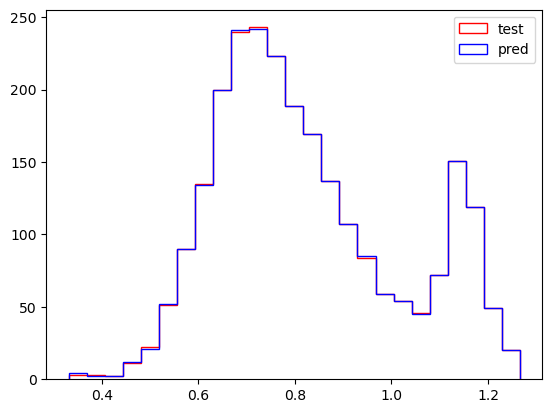

In [28]:
_, bins, _ = plt.hist(target, label='test', histtype='step', bins=25, color='r')
plt.hist(pred, label='pred', histtype='step', bins=bins, color='b')
plt.legend()
plt.show()

In [29]:
# Compute Spearman
from scipy import stats
res = stats.spearmanr(target, pred)
print('Spearman coefficent = ', res)

Spearman coefficent =  SignificanceResult(statistic=0.6615832097866639, pvalue=5.33235775889e-312)
